# Job 51853969 — what does weight sharing actually cost?

**Stage P** tied the attention-only cell's 16 blocks into **one shared block**
at `d192` and the result **CENSORED**: no `rho` bin cleared a 0.5 solve rate, so
there was no `rho_50` to quote. A censor is not a number, and two readings fitted
it equally well:

| reading | what it says | what would distinguish it |
|---|---|---|
| **sharing obstructs** | one block cannot run 16 rounds of deduction | more capacity at fixed sharing changes nothing |
| **capacity floor** | `d192` is too small to hold a block serving 16 roles | more capacity at fixed sharing un-censors it |

**Stage S** is that distinguishing experiment: the same tied cell at
`d192 → d320 → d448`, `T=16` applications throughout, three seeds each, and
nothing else varied. Sharing is held **fixed** — that is the whole design.

The bars are reused, not refrozen around this run: `rho_50` free line **0.740**
(stage K), plateau **1.64** (stage C), leave-one-out residual bar **0.0423**
(stage J), and H1's censoring floor **879,418** trainable parameters, which sits
*between* `d320` (613,818) and `d448` (1,088,698) — the reason `d448` was in the
design at all.

`rho_50` is the realized hint density at which the solve rate crosses 0.5, on a
14-point grid of 400 instances per bin. **Lower is better.** Every eval here is
leak-free (`--shuffle-adj`) and uses `--fall`, so the grid reaches `rho` 0.33.

## Provenance

Recorded so the numbers can be traced: array job, commit, config and seeds.

In [1]:
import json, os, subprocess, sys
sys.path.insert(0, "/home/users/hshunt/spin_gnn")
sys.path.insert(0, "/home/users/hshunt/.local/lib/claude-slides")

from scripts.stages_score import SCAN_S, P1, S1, S2, tied_count, untied_count
from scripts.stagep_score import SCAN_P, CENSOR_FLOOR

CKPT = os.path.join(SCAN_S, "t00_d0320_ff01024_h04_tied_no_mlp_L16_s0",
                    "d0320_h04_L16_ff01024_lr1e-03_pre_shuf_fall_noff_tied")
cfg = json.load(open(os.path.join(CKPT, "config.json")))
print("array job        51853969  (6 cells: d320 x 3 seeds, d448 x 3 seeds)")
print("commit           ", subprocess.run(["git", "rev-parse", "--short", "HEAD"],
      cwd="/home/users/hshunt/spin_gnn", capture_output=True,
      text=True).stdout.strip())
print("run dir          ", SCAN_S)
print("seeds             0, 1, 2 per width")
for k in ("n_nodes", "degree", "n_colors", "arch_mode", "num_layers", "d_model",
          "nhead", "dim_feedforward", "n_train_instances", "epochs", "lr",
          "shuffle_adj", "fall", "warmup_frac", "n_trainable_params"):
    if k in cfg:
        print("  %-20s %s" % (k, cfg[k]))
print()
print("tied d320 trainable  {:,}".format(tied_count(320)))
print("untied twin J2       {:,}  ({:.1f}x larger)".format(
    untied_count(192, 16), untied_count(192, 16) / tied_count(320)))
print("H1 censoring floor   {:,}".format(CENSOR_FLOOR))

array job        51853969  (6 cells: d320 x 3 seeds, d448 x 3 seeds)
commit            d9b177f
run dir           /scratch/users/hshunt/spin_gnn/sudoku_n48_tiedwidth_S_2026-11-10
seeds             0, 1, 2 per width
  n_nodes              48
  degree               5
  n_colors             4
  arch_mode            tied_no_mlp
  num_layers           16
  d_model              320
  nhead                4
  dim_feedforward      1024
  n_train_instances    240000
  epochs               50
  lr                   0.001
  shuffle_adj          True
  fall                 True
  n_trainable_params   613818

tied d320 trainable  613,818
untied twin J2       2,504,890  (4.1x larger)
H1 censoring floor   879,418


## The registered scorer, run as a subprocess

`scripts/stages_score.py` fixes the readings S0–S5, the guards and the bars, and
was committed before the first cell trained. It is run here rather than
reimplemented, so this notebook cannot quietly disagree with the registration.

Read in the order it prints: **S2 (accuracy) before S1 (plateau) before S0
(level)** — accuracy never censors, which is why it is read first.

In [2]:
out = subprocess.run([sys.executable, "-u", "-m", "scripts.stages_score"],
                     cwd="/home/users/hshunt/spin_gnn", capture_output=True,
                     text=True)
print(out.stdout)
if out.returncode:
    print("scorer rc=%d" % out.returncode)
    print(out.stderr[-2000:])

STAGE S -- tied attention-only: buy the capacity back, sharing fixed
  scanning: /scratch/users/hshunt/spin_gnn/sudoku_n48_tiedwidth_S_2026-11-10 /scratch/users/hshunt/spin_gnn/sudoku_n48_tied_P_2026-11-10 /scratch/users/hshunt/spin_gnn/sudoku_n48_minarch_H_2026-11-05 /scratch/users/hshunt/spin_gnn/sudoku_n48_minarch_I_2026-11-05 /scratch/users/hshunt/spin_gnn/sudoku_n48_minarch_J_2026-11-05 /scratch/users/hshunt/spin_gnn/sudoku_n48_minarch_K_2026-11-09 /scratch/users/hshunt/spin_gnn/sudoku_n48_minarch_2026-11-04 /scratch/users/hshunt/spin_gnn/sudoku_n48_minarch_L6_2026-11-04 /scratch/users/hshunt/spin_gnn/sudoku_n48_minarch_C_2026-11-04 /scratch/users/hshunt/spin_gnn/sudoku_n48_minarch_D_2026-11-04
  bars (N=48, reused not refrozen): s* 0.1484 rho_50 / 0.2918 mean_solve, free 0.74, plateau 1.64, LOO 0.0423
  stage M's N=96 bars are a different size and appear nowhere below.
  the width trend at FIXED sharing: 270,010 -> 613,818 -> 1,088,698 trainable, T=16 throughout
  H1's censoring 

## Metrics table

Every row read through the scorer's own `rung` / `summarize` / `escapes` /
`rho_txt` / `acc_of`, pooled over the same directories the scorer scans.
`CENSORED` is printed as itself and never as a number.

In [3]:
from notebooks.make_stages_deck import (CELLS as DECK_CELLS, J2, J2_ACC,
                                        load_everything, curve_rows,
                                        s4_residuals, tied_cells, history)
from scripts.stages_score import BASELINE_DIRS
from scripts.minarch_analysis import SCAN_DIRS
from scripts.stagec_score import rho_txt, PLATEAU

SCAN = [SCAN_S] + BASELINE_DIRS + SCAN_DIRS
D = load_everything(SCAN)

hdr = ("cell", "trainable", "rho_50", "mean_solve", "val_acc", "escapes", "crossed")
print("%-16s %10s %9s %11s %8s %8s %8s" % hdr)
for key, label in DECK_CELLS:
    s = D[key]["s"]
    print("%-16s %10s %9s %11.4f %8.4f %8s %8s" % (
        label, "{:,}".format(s["trainable"]), rho_txt(s), s["mean_solve"],
        D[key]["acc_median"], "%d/%d" % (D[key]["n_esc"], s["n"]),
        "%d/%d" % (s["n_cross"], s["n"])))
print()
print("final train NLL per seed")
for key in (P1, S1, S2):
    print("  %-16s %s" % (D[key]["label"],
          " / ".join("%.4f" % v for v in D[key]["nll"])))
print("  plateau bar %.2f (stage C, reused)" % PLATEAU)

cell              trainable    rho_50  mean_solve  val_acc  escapes  crossed
P1 tied d192        270,010  CENSORED      0.0268   0.4567      0/3      1/3
S1 tied d320        613,818     0.757      0.3148   0.4830      3/3      3/3
S2 tied d448      1,088,698  CENSORED      0.0000   0.0412      1/3      1/3
J2 untied d192    2,504,890     0.580      0.5527   0.4940      3/3      3/3

final train NLL per seed
  P1 tied d192     1.6646 / 1.6721 / 1.6681
  S1 tied d320     1.5851 / 1.5915 / 1.5864
  S2 tied d448     1.5815 / 3.7874 / 3.9199
  plateau bar 1.64 (stage C, reused)


## S1 — the plateau, read before any level

Registered: final train NLL falls monotonically across the three widths. A flat
trend would mean the floor belongs to the tied **object** and no width moves it.
The trajectory is shown, not just the final number: a seed that *escaped* the
plateau and one that *sat on* it can end at similar NLL only if neither moved.

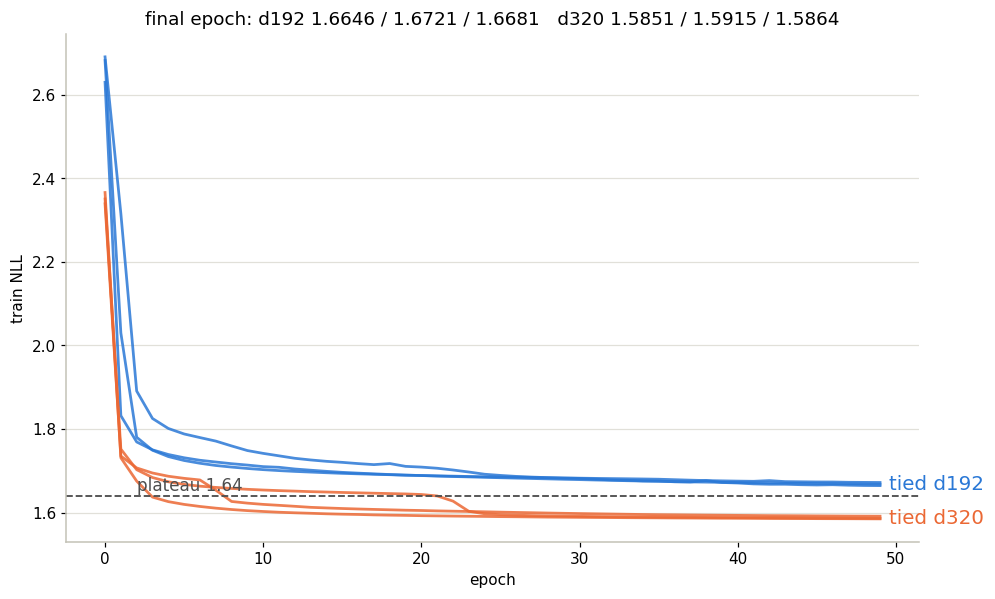

In [4]:
import matplotlib.pyplot as plt
from notebooks.make_stages_deck import draw_nll, draw_curves, draw_accuracy, \
     draw_rho50, draw_s4, draw_resid

h192, h320 = history(P1, SCAN_P), history(S1, SCAN_S)
fig, ax = plt.subplots(figsize=(10, 6))
draw_nll(ax, [h192, h320], ["tied d192", "tied d320"])
ax.set_title("final epoch: d192 %s   d320 %s" % (
    " / ".join("%.4f" % v for v in D[P1]["nll"]),
    " / ".join("%.4f" % v for v in D[S1]["nll"])))
plt.show()

## S0 — the level: the solve curves themselves

Stage P's `d192` never reaches the 0.5 line at any density; `d320` crosses it on
all three seeds. The x-axis is **realized** `rho`, never requested: below an
ensemble's `rho_min` every requested point collapses onto the floor, and a flat
tail there is one point drawn many times.

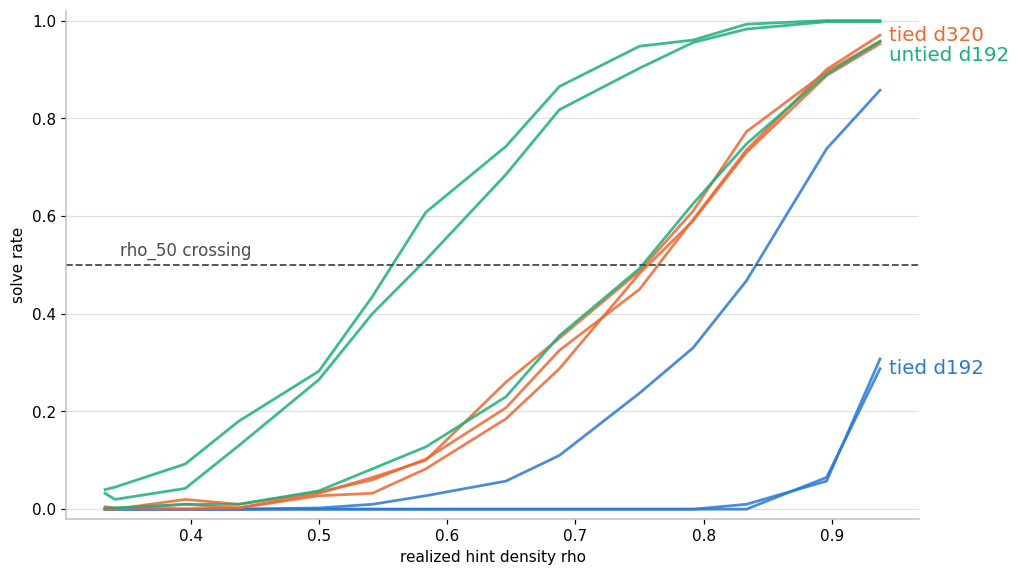

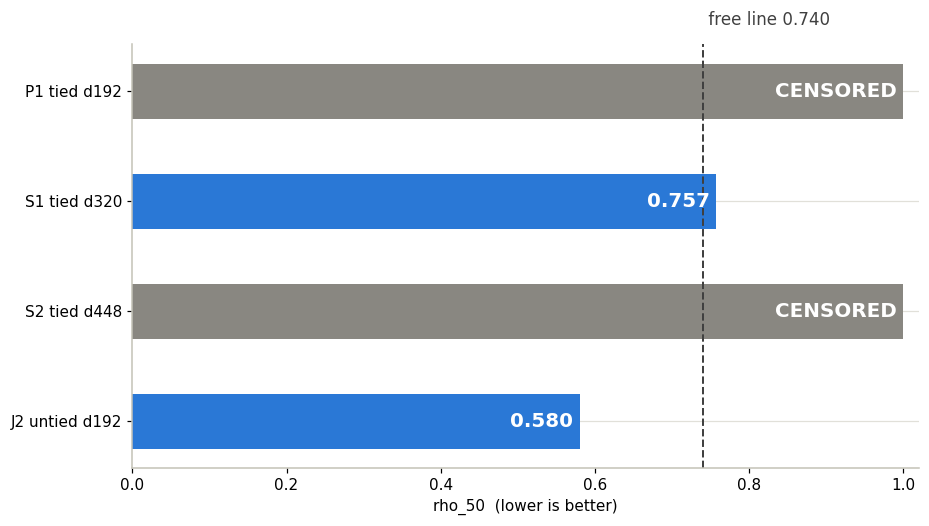

In [5]:
by = curve_rows(SCAN)
fig, ax = plt.subplots(figsize=(10, 6))
draw_curves(ax, by, [P1, S1, J2], ["tied d192", "tied d320", "untied d192"])
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
draw_rho50(ax, [D[k]["label"] for k, _ in DECK_CELLS],
           [float(rho_txt(D[k]["s"])) if rho_txt(D[k]["s"]) != "CENSORED"
            else float("nan") for k, _ in DECK_CELLS],
           [rho_txt(D[k]["s"]) == "CENSORED" for k, _ in DECK_CELLS])
plt.show()

## S2 — accuracy against width

Read first in the scorer's order, plotted here after the curves because the
curves are what the width was bought for. The untied twin's level is the thing
width is trying to reach.

P1 tied d192     s0 0.4715  s1 0.4561  s2 0.4567
S1 tied d320     s0 0.4822  s1 0.4830  s2 0.4833
S2 tied d448     s0 0.4831  s1 0.0412  s2 0.0308
untied twin J2   0.4940


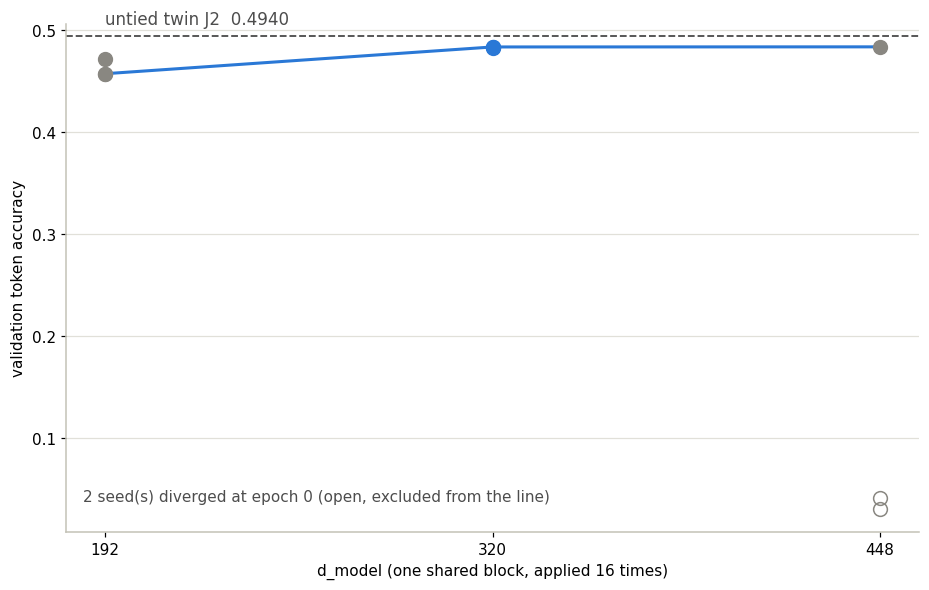

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))
draw_accuracy(ax, [192, 320, 448], [(k, D[k]["accs"]) for k in (P1, S1, S2)],
              J2_ACC)
plt.show()
for k in (P1, S1, S2):
    print("%-16s %s" % (D[k]["label"],
          "  ".join("s%d %.4f" % (s, a) for s, a in D[k]["accs"])))
print("untied twin J2   %.4f" % J2_ACC)

## The `d448` arm, reported rather than dropped

Two of three `d448` seeds diverged at epoch 0. Diagnostic job `51860479` traced
that to **warmup**, not to the cell: the same cell with warmup trained. So
`d448` carries one usable seed and cannot support a 3-seed reading, and every
quoted number in this notebook is `d320`'s. The surviving `d448` seed is
reported for what it is — a single seed, 0.0001 of token accuracy above `d320`'s
median (0.4831 against 0.4830), which is why the conclusion drawn from it is
only that accuracy has **saturated in width**.

**This is why the scorer's printed `S0 FALSIFIED` is not this notebook's
verdict.** S0 was registered on the `d448` arm — "3 of 3 cross and median
`rho_50` ≤ 0.74 at a width above H1's censoring floor" — and the arm came back
CENSORED with **escapes 1/3** and a median train NLL of 3.7874, i.e. the uniform
predictor. The scorer's own precedence rule, printed directly above it, is that
**S1 outranks S0: "a cell that never left the plateau says nothing about tying,
only about training it."** Two `d448` seeds never left the plateau, so the
censor they produce is an optimization failure and not a statement about
sharing. The scorer has no branch for a cell that fails to *train* — a fourth
outcome beside pass, censor and past-the-line — so it applied the censor branch
and printed a conclusion its own premise ("with the plateau escaped") does not
support. The reading that survives is `d320`'s: **3/3 crossing, `rho_50` 0.757,
0.017 past the free line.**

## S4 — does tying change the accuracy-to-solve *relation*?

The decisive check, registered before the run and run as job `51904215`. The
N=48 depth ladder defines an isotonic accuracy → solve curve; stage J measured
its leave-one-out residual bar at **0.0423**. If the tied cells sit **on** that
curve, tying costs accuracy and nothing else, and the whole `rho_50` gap is what
the accuracy gap buys at this steepness. If they sit **off** it, tying changes
the relation, which is a larger claim than any level.

A cell only tests the curve if its prediction is away from the 0.10 floor — a
cell predicted at the floor cannot fail. Those are reported separately.

**The held-out population here is larger than S4's registered run saw** — 46
discriminating cells against 30 — because the `rho_curve_*.csv` glob fix made
stage T's grids visible to the loader. The three `d320` residuals are unchanged
to the digit, but the *widest* miss in the enlarged population is **outside** the
0.0423 bar; the list below names it. So the bar is read here as what stage J
froze it as, a threshold for these three seeds, and not as a claim that every
held-out cell in the fit clears it.

reference cells 21, held-out 81, discriminating 46

seed        acc  predicted   observed   residual   bracket discriminating
s0       0.4822     0.3079     0.3245    +0.0165    0.0008 True
s1       0.4830     0.3082     0.3048    -0.0034    0.0008 True
s2       0.4833     0.3083     0.3148    +0.0065    0.0008 True

worst |residual| among all 46 discriminating held-out cells: 0.0729
the five widest misses, by rung:
  +0.0729  seed 0  pred 0.1298  obs 0.2027  rung (16, 4, 'tied_no_mlp', 192, 1024, 0)
  +0.0518  seed 2  pred 0.1841  obs 0.2359  rung (6, 4, 'no_mlp', 128, 1024, 0)
  +0.0400  seed 2  pred 0.5632  obs 0.6032  rung (12, 4, 'no_mlp', 224, 1024, 0)
  +0.0326  seed 1  pred 0.5524  obs 0.5850  rung (16, 4, 'no_mlp', 192, 1024, 0)
  +0.0273  seed 0  pred 0.2784  obs 0.3057  rung (4, 4, 'no_mlp')


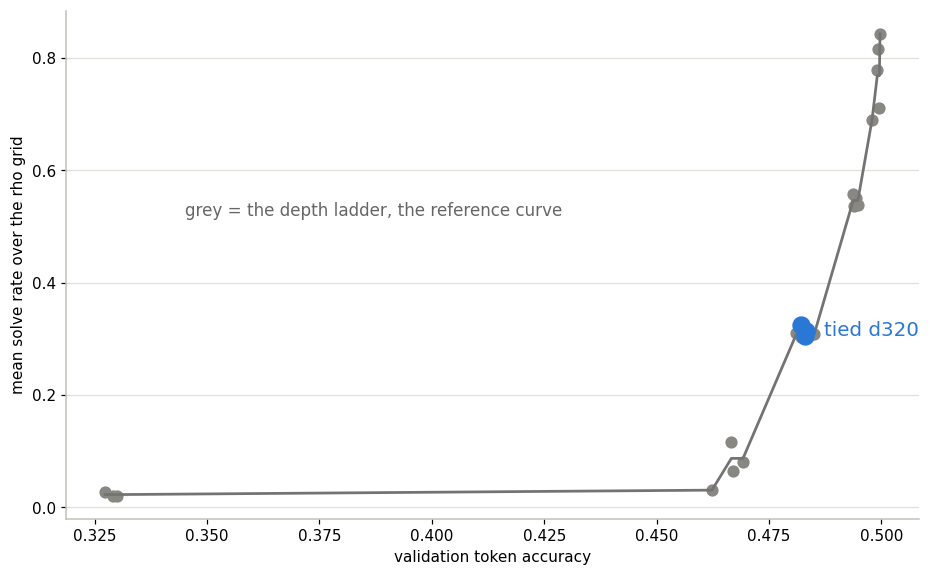

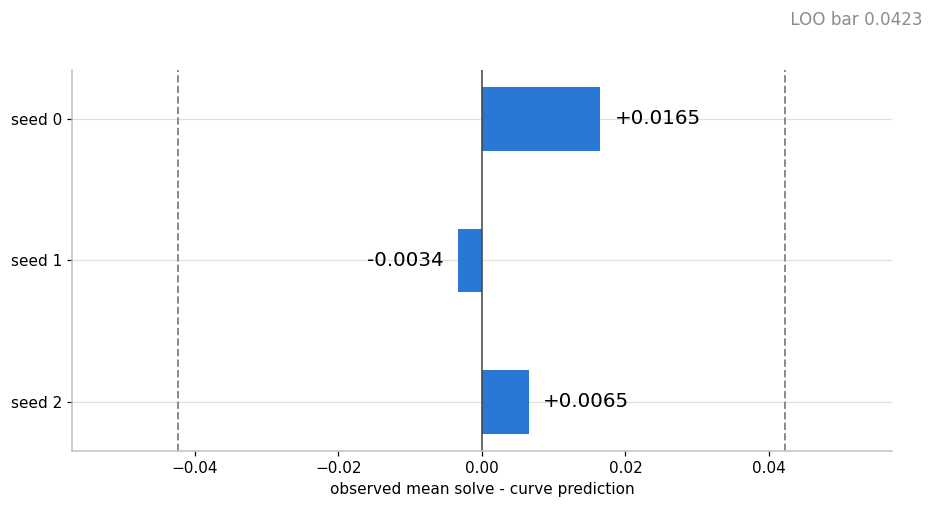

In [7]:
ref, fit, resids = s4_residuals(SCAN)
t320 = tied_cells(resids, S1)
print("reference cells %d, held-out %d, discriminating %d"
      % (len(ref), len(resids), sum(r["discriminating"] for r in resids)))
print()
print("%-6s %8s %10s %10s %10s %9s %s" % ("seed", "acc", "predicted", "observed",
                                          "residual", "bracket", "discriminating"))
for r in t320:
    print("%-6s %8.4f %10.4f %10.4f %+10.4f %9.4f %s"
          % ("s%d" % r["seed"], r["acc"], r["pred"], r["mean_solve"], r["resid"],
             r["cov"], r["discriminating"]))
disc = [r for r in resids if r["discriminating"]]
print()
print("worst |residual| among all %d discriminating held-out cells: %.4f"
      % (len(disc), max(abs(r["resid"]) for r in disc)))
# Named, not just counted. S4's registered run saw 30 discriminating cells and
# a worst miss of 0.0222; this fit sees more cells because the rho_curve_*.csv
# glob fix made stage T's grids visible to the loader, and the worst miss it
# finds is LARGER than the 0.0423 bar. Which cell that is matters: the rung is
# printed as the tuple because rung_label() reads a 7-tuple's tail as `epochs`.
print("the five widest misses, by rung:")
for r in sorted(disc, key=lambda r: -abs(r["resid"]))[:5]:
    print("  %+.4f  seed %d  pred %.4f  obs %.4f  rung %s"
          % (r["resid"], r["seed"], r["pred"], r["mean_solve"], r["rung"]))

fig, ax = plt.subplots(figsize=(10, 6))
draw_s4(ax, ref, fit, t320)
plt.show()

fig, ax = plt.subplots(figsize=(10, 4.5))
draw_resid(ax, t320)
plt.show()

## Comparison against the previous best on the same eval

`J2` — untied `no_mlp L=16 d192`, finding 53's standing minimum — is the
previous best on this identical eval: same 14-point grid, same 400 instances per
bin, same `--shuffle-adj --fall`, same N=48 ensemble.

**No improvement is claimed.** The tied cell is 4.1x smaller and conceptually
simpler (one block instead of sixteen) and it is **worse** on the eval.

In [8]:
s1, j2 = D[S1], D[J2]
rows = [("rho_50 median (lower better)", rho_txt(j2["s"]), rho_txt(s1["s"])),
        ("mean solve", "%.4f" % j2["s"]["mean_solve"], "%.4f" % s1["s"]["mean_solve"]),
        ("val token accuracy", "%.4f" % J2_ACC, "%.4f" % s1["acc_median"]),
        ("trainable", "{:,}".format(untied_count(192, 16)),
         "{:,}".format(tied_count(320))),
        ("distinct blocks", "16", "1"),
        ("seeds crossing 0.5", "3/3", "%d/%d" % (s1["s"]["n_cross"], s1["s"]["n"]))]
print("%-30s %22s %22s" % ("quantity", "J2 untied d192 (prev best)", "S1 tied d320"))
for a, b, c in rows:
    print("%-30s %22s %22s" % (a, b, c))

quantity                       J2 untied d192 (prev best)           S1 tied d320
rho_50 median (lower better)                    0.580                  0.757
mean solve                                     0.5527                 0.3148
val token accuracy                             0.4940                 0.4830
trainable                                   2,504,890                613,818
distinct blocks                                    16                      1
seeds crossing 0.5                                3/3                    3/3


## What stage S does not show

- **N=48 only.** Stage M's N=96 bars are a different size and appear nowhere above.
- **`T=16` at train time only.** No tied cell has been trained at another depth,
  so nothing here says 16 is the right number of applications — only that it is
  the number this cell was trained with.
- **No counterfactual audit of the tied cell.** Stages Q and R edited hints and
  derived facts on the *untied* cell. Whether the shared block flips its answer
  when a premise changes is untested.
- **The guard third of findings 27/28** — declining to deduce what does not
  follow — remains unmeasured on any `no_mlp` cell.

## What it licenses next

A tied stack has one dial no untied stack has: **how many times the block is
applied at eval**. 16 is a trained count, not a structural property. If the
shared block is an iterable deduction *operator*, quality should hold when it is
applied more than 16 times on fixed weights; if depth 16 is a trained
*schedule*, quality should peak at exactly 16 and fall on both sides. That is
**stage T** (`scripts/staget_score.py`, registered before its cells ran), which
needs no training at all.

**Stage T has since answered it, and the answer is the schedule one** (array
`51904636`, scored by job `51919538`, read in the registered order T1 → level
table → T0). The same frozen d320 weights applied `T ∈ {4,8,12,16,20,24}` give
`rho_50` CENSORED / CENSORED / 0.769 / **0.757** / 0.763 / 0.819: the level
bottoms at the trained count and `mean_solve` peaks there, `|T24 − T16|` is
0.062 against a 0.01 bar, and T1 — the easy end, which cannot censor — fails,
with all three seeds below the 0.90 bar at T=24 (0.000 / 0.550 / 0.882) and one
seed collapsing outright. T1 outranks T0 by registration, so the shared block is
read as one weight set tuned to a 16-step schedule rather than an operator that
can be iterated. Stage S's result is unaffected — stage T trained nothing — but
the "what it licenses next" above is no longer open: the cut it points to is
**k distinct blocks cycled T/k times**, which is stage U.